<a href="https://colab.research.google.com/github/jurados/alercehackton2026/blob/main/ZTF_candidates.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [39]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from tqdm.auto import tqdm

import sncosmo
from astropy.timeseries import LombScargle
from astropy.coordinates import SkyCoord, GeocentricTrueEcliptic
import astropy.units as u
from dustmaps.config import config
from dustmaps.sfd import SFDQuery

from alerce.core import Alerce

In [4]:
# Create an Alerce client
client = Alerce()

print("Querying classifiers for ZTF survey...")
print(f"{help(client)}")

Querying classifiers for ZTF survey...
Help on Alerce in module alerce.core object:

class Alerce(alerce.common_search.AlerceCommonSearch, alerce.crossmatch.AlerceXmatch, alerce.common_stamps.AlerceCommonStamps)
 |  Alerce(ztf_backend: Literal['legacy', 'multisurvey'] = 'legacy', **kwargs)
 |
 |  The ALeRCE Client for accessing astronomical data from multiple surveys.
 |
 |  This is the main entry point for the ALeRCE Python Client. It provides unified
 |  access to query astronomical objects, photometry, classifications, stamps, and
 |  perform crossmatching operations across multiple surveys.
 |
 |  Examples
 |  --------
 |  Basic usage:
 |
 |  >>> from alerce.core import Alerce
 |  >>> client = Alerce()
 |
 |  Query objects from ZTF:
 |
 |  >>> objects = client.query_objects(
 |  ...     survey="ztf",
 |  ...     ra=10.0,
 |  ...     dec=-20.0,
 |  ...     radius=30
 |  ... )
 |
 |  Get a lightcurve:
 |
 |  >>> lc = client.query_lightcurve("ZTF21aaeyldq", survey="ztf")
 |
 |  Retrie

In [5]:
# Query classifiers for ZTF survey in pandas format
cls = client.query_classifiers(format="pandas", survey="ztf")
print(cls.columns)
display(cls.head(20))

/tmp/ipykernel_206375/238045344.py:2: FutureWarning: The default ZTF backend will change from 'legacy' to 'multisurvey' in a future release. To adopt early, use Alerce(ztf_backend='multisurvey').
  cls = client.query_classifiers(format="pandas", survey="ztf")


Index(['classifier_name', 'classifier_version', 'classes'], dtype='str')


,classifier_name,classifier_version,classes
0,lc_classifier_transient,hierarchical_random_forest_1.0.0,"[SNIa, SNIbc, SNII, SLSN]"
1,lc_classifier_stochastic,hierarchical_random_forest_1.0.0,"[QSO, AGN, Blazar, CV/Nova, YSO]"
2,lc_classifier_periodic,hierarchical_random_forest_1.0.0,"[LPV, E, DSCT, RRL, CEP, Periodic-Other]"
3,LC_classifier_ATAT_forced_phot(beta),beta,"[SNIa, SNIbc, SNIIb, SNII, SNIIn, SLSN, TDE, M..."
4,LC_classifier_BHRF_forced_phot(beta),beta,"[SNIa, SNIbc, SNIIb, SNII, SNIIn, SLSN, TDE, M..."
5,lc_classifier,hierarchical_random_forest_1.0.0,"[SNIa, SNIbc, SNII, SLSN, QSO, AGN, Blazar, CV..."
6,lc_classifier_top,hierarchical_random_forest_1.0.0,"[Transient, Stochastic, Periodic]"
7,stamp_classifier,stamp_classifier_1.0.0,"[SN, AGN, VS, asteroid, bogus]"
8,stamp_classifier,stamp_classifier_1.0.4,"[SN, AGN, VS, asteroid, bogus]"
9,lc_classifier_BHRF_forced_phot,2.1.0,"[SNIa, SESN, SNII, SNIIn, SLSN, TDE, Microlens..."


In [6]:
# We select only the SNIa candidates with lastmjd >= 60918 (1 Sept 2025)
# This because we want to select only the candidates that are recent and have a high probability of being SNIa
START_MJD = 60918

# Query objects classified as SNIa with probability >= 0.59,
# using the lc_classifier_BHRF_forced_phot classifier, ordered by lastmjd in descending order,
# with a page size of 2000, and return the results in pandas format
df = client.query_objects(
    survey      = "ztf",
    classifier  = "lc_classifier_BHRF_forced_phot",
    class_name  = "SNIa",
    probability = 0.59,
    order_by    = "lastmjd",
    order_mode  = "DESC",
    page_size   = 2000,
    format      = "pandas"
)
print("Número de candidatos SNIa encontrados:", df.shape[0])
print(df.columns)
print(df.dtypes)

Número de candidatos SNIa encontrados: 285
Index(['oid', 'ndethist', 'ncovhist', 'mjdstarthist', 'mjdendhist',
       'corrected', 'stellar', 'ndet', 'g_r_max', 'g_r_max_corr', 'g_r_mean',
       'g_r_mean_corr', 'firstmjd', 'lastmjd', 'deltajd', 'meanra', 'meandec',
       'sigmara', 'sigmadec', 'class', 'classifier', 'probability',
       'step_id_corr'],
      dtype='str')
oid                  str
ndethist             str
ncovhist           int64
mjdstarthist     float64
mjdendhist       float64
corrected           bool
stellar             bool
ndet               int64
g_r_max           object
g_r_max_corr      object
g_r_mean          object
g_r_mean_corr     object
firstmjd         float64
lastmjd          float64
deltajd          float64
meanra           float64
meandec          float64
sigmara          float64
sigmadec         float64
class                str
classifier           str
probability      float64
step_id_corr         str
dtype: object


In [7]:
# We select only the SNIa candidates with lastmjd >= 60918 (1 Sept 2025)
df_snia = df[df["lastmjd"] >= START_MJD]

print("Número de SNIa encontradas:", len(df_snia))
print(df_snia.columns)

Número de SNIa encontradas: 226
Index(['oid', 'ndethist', 'ncovhist', 'mjdstarthist', 'mjdendhist',
       'corrected', 'stellar', 'ndet', 'g_r_max', 'g_r_max_corr', 'g_r_mean',
       'g_r_mean_corr', 'firstmjd', 'lastmjd', 'deltajd', 'meanra', 'meandec',
       'sigmara', 'sigmadec', 'class', 'classifier', 'probability',
       'step_id_corr'],
      dtype='str')


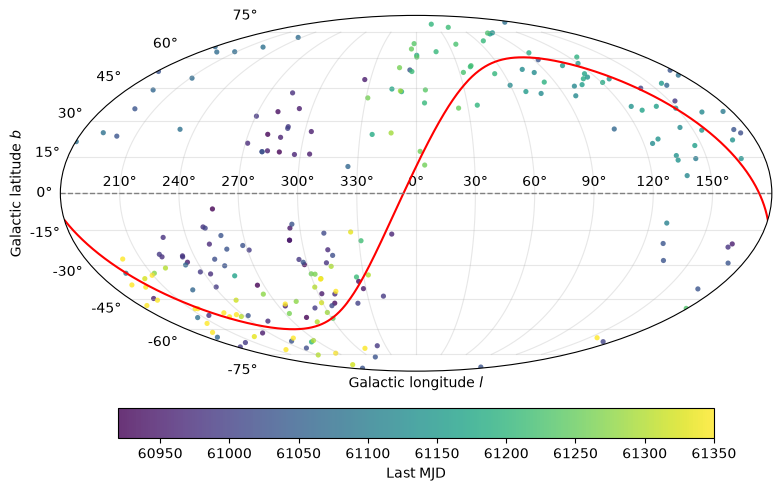

In [8]:
fig = plt.figure(figsize=(11, 6))
ax = fig.add_subplot(projection="mollweide")

t = np.linspace(0, 360, 2000) * u.deg

# Ecliptic
ecl = SkyCoord(lon=t, lat=np.zeros(t.size)*u.deg, frame=GeocentricTrueEcliptic).galactic
el = -ecl.l.wrap_at(180*u.deg).radian
eb = ecl.b.radian
idx = np.argsort(el)
ax.plot(el[idx], eb[idx], color="red", lw=1.5, label="Ecliptic")

# Galactic plane
ax.axhline(0, color="gray", lw=1, ls="--", label="Galactic plane")

# Data (newest on top)
c = SkyCoord(ra=df_snia["meanra"].to_numpy()*u.deg, dec=df_snia["meandec"].to_numpy()*u.deg).galactic
l = -c.l.wrap_at(180*u.deg).radian
b = c.b.radian
mjd = df_snia["lastmjd"].to_numpy()
o = np.argsort(mjd)
sc = ax.scatter(l[o], b[o], s=14, c=mjd[o], cmap="viridis", alpha=0.8, edgecolor="none")

ax.set_xticklabels(["210°", "240°", "270°", "300°", "330°", "0°", "30°", "60°", "90°", "120°", "150°"])
ax.set_xlabel("Galactic longitude $l$")
ax.set_ylabel("Galactic latitude $b$")
ax.grid(True, alpha=0.3)
fig.colorbar(sc, ax=ax, orientation="horizontal", label="Last MJD", pad=0.08, shrink=0.7)
plt.show()


Cada posición (RA = α, Dec = δ) se convierte en un punto sobre la esfera unidad:

$$\hat r = (\cos\delta\cos\alpha, \cos\delta\sin\alpha, \sin\delta)$$

Astropy construye un árbol KD (`scipy.spatial.cKDTree`) con los vectores del catálogo (`coords_tns`). Luego consulta, para cada candidata, el punto más cercano en distancia euclídea (la cuerda). Esto es O(N log M), en vez de O(N·M) comparando todos contra todos.
Si dos puntos unitarios están separados por una cuerda $c$, el ángulo entre ellos es:

$$\theta = 2\arcsin \left(\dfrac c2\right)$$

Este $\theta$ es `sep2d`.


Querying TNS public objects...
Número de objetos en TNS: 191101
Index(['objid', 'name_prefix', 'name', 'ra', 'declination', 'redshift',
       'typeid', 'type', 'reporting_groupid', 'reporting_group',
       'source_groupid', 'source_group', 'discoverydate', 'discoverymag',
       'discmagfilter', 'filter', 'reporters', 'time_received',
       'internal_names', 'Discovery_ADS_bibcode', 'Class_ADS_bibcodes',
       'creationdate', 'lastmodified'],
      dtype='str')


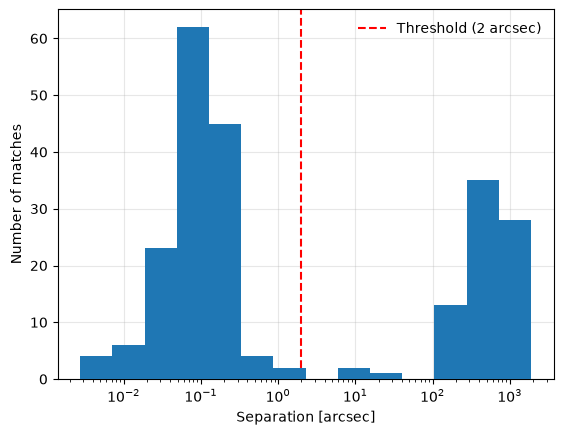

In [9]:
print("\nQuerying TNS public objects...")
tns = pd.read_csv("data/tns_public_objects.csv", skiprows=1, low_memory=False)
print("Número de objetos en TNS:", len(tns))
print(tns.columns)

#print("\nColumnas TNS:")
#print(tns.columns.tolist())

# Convierte las columnas a tipo numérico, ignorando errores
# Además, eliminamos filas con valores NaN en las columnas de coordenadas
tns["ra"]          = pd.to_numeric(tns["ra"], errors="coerce")
tns["declination"] = pd.to_numeric(tns["declination"], errors="coerce")
tns["redshift"]    = pd.to_numeric(tns["redshift"], errors="coerce")
tns = tns.dropna(subset=["ra", "declination"]).reset_index(drop=True)

# Cambio de coordenadas
coords_snia = SkyCoord(ra=df_snia["meanra"].values * u.deg, dec=df_snia["meandec"].values * u.deg)
coords_tns  = SkyCoord(ra=tns["ra"].values * u.deg, dec=tns["declination"].values * u.deg)

# Matching usando match_to_catalog_sky
# El método match_to_catalog_sky encuentra el objeto más cercano en el catálogo de TNS para cada objeto en df_snia
# Devuelve tres valores:
# - idx:    los índices de los objetos coincidentes en el catálogo de TNS
# - sep2d:  la separación angular entre los objetos coincidentes
# - dist3d: la separación 3D (no se utiliza en este caso)
# Se pueden cambiar los siguientes parámetros:
# - nthneighbor: el número de vecinos a considerar (por defecto es 1, es decir, el vecino más cercano)
# - storekdtree: si se debe almacenar el árbol k-d para acelerar las búsquedas (por defecto es True)
# - max_sep: la separación máxima para considerar un objeto como coincidente, 
# puede ser un valor en arcsec (por ejemplo, 2.0 * u.arcsec)
idx, sep2d, dist3d = coords_snia.match_to_catalog_sky(coords_tns)



fig, ax = plt.subplots()
n    = int(np.sqrt(len(sep2d)))  # Número de bins usando la regla de raíz cuadrada
bins = np.logspace(np.log10(sep2d.arcsec.min()), np.log10(sep2d.arcsec.max()), n)
ax.hist(sep2d.arcsec, bins=bins, zorder=3)
ax.set_xscale("log")
ax.axvline(2, color="red", ls="--", label="Threshold (2 arcsec)")
ax.set_xlabel("Separation [arcsec]")
ax.set_ylabel("Number of matches")
ax.legend(frameon=False)
ax.grid(True, alpha=0.3)
plt.show()

In [10]:
# Habiendo visualizado la distribución de separaciones, podemos establecer un umbral de matching.
# siendo este de 2 arcsec.
threshold_sep = 2.0 * u.arcsec
matched = sep2d <= threshold_sep

df_snia["tns_match"] = matched
df_snia["tns_sep_arcsec"] = sep2d.arcsec

cols = {"name": "tns_name", "name_prefix": "tns_name_prefix", "type": "tns_type", "redshift": "tns_redshift"}

tns_matched = (
    tns.iloc[idx][list(cols)]
    .rename(columns=cols)
    .set_index(df_snia.index)
)

tns_matched.loc[~matched] = np.nan   # blank out rows without a match
df_snia[tns_matched.columns] = tns_matched
df_snia["tns_full_name"] = (df_snia["tns_name_prefix"] + " " + df_snia["tns_name"]).where(matched)

print("\nMatches encontrados:", int(df_snia["tns_match"].sum()))
display(df_snia.head())


Matches encontrados: 146


,oid,ndethist,ncovhist,mjdstarthist,mjdendhist,corrected,stellar,ndet,g_r_max,g_r_max_corr,...,classifier,probability,step_id_corr,tns_match,tns_sep_arcsec,tns_name,tns_name_prefix,tns_type,tns_redshift,tns_full_name
0,ZTF26abwqfcv,58,2160,61304.507824,61350.405197,True,False,57,None,None,...,lc_classifier_BHRF_forced_phot,0.664668,27.6.0,False,1821.249040,NaN,NaN,NaN,NaN,NaN
1,ZTF26absfire,173,4221,61286.426030,61350.391123,False,False,172,None,None,...,lc_classifier_BHRF_forced_phot,0.713136,27.6.0,False,516.541359,NaN,NaN,NaN,NaN,NaN
2,ZTF26abnuiar,127,3170,61264.487512,61350.382211,False,False,127,None,None,...,lc_classifier_BHRF_forced_phot,0.655720,27.6.0,False,1113.374688,NaN,NaN,NaN,NaN,NaN
3,ZTF26acbezdh,31,1925,61327.421296,61350.382211,False,False,30,None,None,...,lc_classifier_BHRF_forced_phot,0.742608,27.6.0,False,1046.942230,NaN,NaN,NaN,NaN,NaN
4,ZTF26abpbqtk,224,3276,61269.475162,61350.382211,True,False,233,None,None,...,lc_classifier_BHRF_forced_phot,0.656476,27.6.0,False,426.464975,NaN,NaN,NaN,NaN,NaN


# Light Curves

In [11]:
from pathlib import Path

outdir = Path("data")
outdir.mkdir(exist_ok=True)

names = ["detections", "non_detections", "forced"]
paths = {n: outdir / f"snia_{n}.parquet" for n in names}
missing = [n for n in names if not paths[n].exists()]

# Download only what is missing
if missing:
    print("Descargando:", missing)
    client = Alerce()
    all_queries = {
        "detections":     client.query_detections,
        "non_detections": client.query_non_detections,
        "forced":         client.query_forced_photometry,
    }
    queries = {n: all_queries[n] for n in missing}
    tables = {n: [] for n in missing}

    pbar = tqdm(df_snia["oid"], desc="Downloading")
    for oid in pbar:
        pbar.set_postfix(oid=oid)
        for name, query in queries.items():
            try:
                tbl = query(oid, format="pandas")
            except Exception as e:
                tqdm.write(f"Error {name} {oid}: {e}")
                continue
            if tbl is not None and len(tbl) > 0:
                tables[name].append(tbl.assign(oid=oid))

    for name, parts in tables.items():
        if parts:
            pd.concat(parts, ignore_index=True).to_parquet(paths[name], index=False)
            print(f"{name}: guardado en {paths[name]}")
        else:
            print(f"{name}: nada que guardar")
else:
    print("Todos los archivos existen en data/, solo se cargan.")

# Load (all three, whether just downloaded or already there)
snia_detections     = pd.read_parquet(paths["detections"])
snia_non_detections = pd.read_parquet(paths["non_detections"])
snia_forced         = pd.read_parquet(paths["forced"])

print('Columns forced:\n', snia_forced.columns.tolist())
print('Columns detections:\n', snia_detections.columns.tolist())
print('Columns non-detections:\n', snia_non_detections.columns.tolist())


Todos los archivos existen en data/, solo se cargan.
Columns forced:
 ['candid', 'tid', 'pid', 'oid', 'mjd', 'fid', 'ra', 'e_ra', 'dec', 'e_dec', 'mag', 'e_mag', 'mag_corr', 'e_mag_corr', 'e_mag_corr_ext', 'isdiffpos', 'corrected', 'dubious', 'parent_candid', 'has_stamp', 'rfid', 'clrcoeff', 'ranr', 'sciinpseeing', 'clrcounc', 'decnr', 'scibckgnd', 'exptime', 'magnr', 'scisigpix', 'adpctdif1', 'sigmagnr', 'magzpsci', 'adpctdif2', 'chinr', 'diffmaglim', 'programid', 'sharpnr', 'field', 'magzpsciunc', 'procstatus', 'rcid', 'magzpscirms', 'distnr']
Columns detections:
 ['tid', 'mjd', 'candid', 'fid', 'pid', 'diffmaglim', 'isdiffpos', 'nid', 'distnr', 'magpsf', 'magpsf_corr', 'magap', 'sigmapsf', 'sigmapsf_corr', 'sigmapsf_corr_ext', 'sigmagap', 'ra', 'dec', 'rb', 'rbversion', 'drb', 'magapbig', 'sigmagapbig', 'rfid', 'has_stamp', 'corrected', 'dubious', 'step_id_corr', 'phase', 'parent_candid', 'oid']
Columns non-detections:
 ['tid', 'mjd', 'fid', 'diffmaglim', 'oid']


In [33]:
def Villar2019(t, A, beta, t0, trise, tfall, gamma, c):
    """
    Parametric SN light curve from Villar et al. 2019
    (https://scixplorer.org/abs/2019ApJ...884...83V/abstract)

    Parameters
    ----------
    t : np.ndarray
        Time array (days)
    A : float
        Amplitude (flux units)
    beta : float
        Slope of the plateau after the rise (flux units / day)
    t0 : float
        Reference time of the rise (days); the sigmoid equals 1/2 here
    trise : float
        Rise timescale (days)
    tfall : float
        Exponential decay timescale after the plateau (days)
    gamma : float
        Duration of the plateau (days); the decay starts at t1 = t0 + gamma
    c : float
        Constant baseline offset (flux units)

    Returns
    -------
    np.ndarray
        Model flux at each time in `t`.
    """
    t  = np.asarray(t, dtype=float)
    t1 = t0 + gamma
    F  = np.zeros_like(t)

    mask_rise = t < t1
    mask_fall = ~mask_rise

    F[mask_rise] = (A + beta*(t[mask_rise] - t0)) / (1 + np.exp(-(t[mask_rise] - t0)/trise))
    F[mask_fall] = ((A + beta*(t1 - t0)) * np.exp(-(t[mask_fall] - t1)/tfall)) / \
                   (1 + np.exp(-(t[mask_fall] - t0)/trise))

    return F + c


ZTF26aaebmad: z=0.0520  Δm15(g) = 1.73


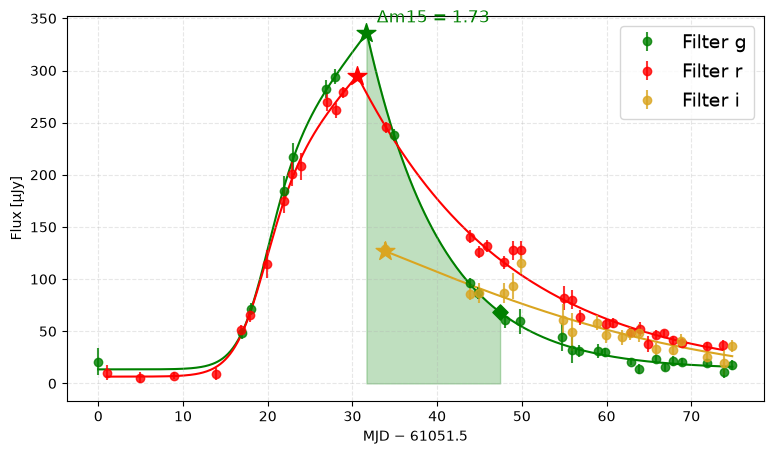

In [64]:
oid_selected = np.random.choice(df_snia["oid"].values, size=1)[0]
SHOW_NONDET  = False
SHADE        = "area"      # "area" = region under the curve, "triangle" = right triangle of the drop

# AB magnitudes -> flux in microJy
mag2flux  = lambda m: 10**(-0.4 * (m - 23.9))
dmag2flux = lambda m, dm: 0.4 * np.log(10) * mag2flux(m) * dm

fo = snia_forced[snia_forced["oid"] == oid_selected]
nd = snia_non_detections[snia_non_detections["oid"] == oid_selected]
fo = fo[(fo.mag < 99) & (fo.e_mag < 1)]            # drop sentinels / non-measurements

z = df_snia.loc[df_snia.oid == oid_selected, "tns_redshift"].iloc[0]

bands = {1: ("g", "green"), 2: ("r", "red"), 3: ("i", "goldenrod")}
tref  = fo.mjd.min()

fig, ax = plt.subplots(figsize=(9, 5))
for fid, (name, color) in bands.items():
    sndata = fo[fo.fid == fid]
    if len(sndata) == 0:
        continue
    t     = sndata.mjd.to_numpy() - tref
    flux  = mag2flux(sndata.mag.to_numpy())
    dflux = dmag2flux(sndata.mag.to_numpy(), sndata.e_mag.to_numpy())

    ax.errorbar(t, flux, yerr=dflux, fmt="o", color=color,
                label=f"Filter {name}", alpha=0.8, zorder=2)

    if len(t) > 7:
        scale = flux.max()
        y, dy = flux / scale, dflux / scale

        p0 = [1.0, 0.0, t[np.argmax(y)] - 10, 5.0, 30.0, 10.0, 0.0]
        lo = [0,   -0.1, t.min()-50, 0.1,   1,   0, -0.1]
        hi = [10,   0.1, t.max(),    50,  200, 100,  0.1]
        try:
            popt, _ = curve_fit(Villar2019, t, y, p0=p0, sigma=dy, absolute_sigma=True,
                                bounds=(lo, hi), maxfev=20000)
        except RuntimeError as e:
            print(f"Fit failed for {name}: {e}")
            continue

        tfit = np.linspace(t.min(), t.max(), 500)
        yfit = Villar2019(tfit, *popt) * scale
        ax.plot(tfit, yfit, color=color, zorder=1)
        i = np.argmax(yfit)
        ax.scatter(tfit[i], yfit[i], color=color, marker="*", s=200, zorder=3)

        # Δm15 in g only
        if fid == 1 and np.isfinite(z):
            t15 = tfit[i] + 15*(1 + z)
            if t15 <= t.max():
                F15  = Villar2019(np.array([t15]), *popt)[0] * scale
                dm15 = 2.5*np.log10(yfit[i] / F15)
                ax.scatter(t15, F15, marker="D", color=color, s=60, zorder=3)

                if SHADE == "area":
                    # area under the fitted curve between the peak and peak + 15 d
                    tt = np.linspace(tfit[i], t15, 100)
                    ax.fill_between(tt, 0, Villar2019(tt, *popt) * scale,
                                    color=color, alpha=0.25, zorder=0)
                else:
                    # right triangle: horizontal leg = 15 d, vertical leg = flux drop
                    ax.fill([tfit[i], t15, t15], [yfit[i], yfit[i], F15],
                            color=color, alpha=0.30, zorder=0)
                    ax.plot([tfit[i], t15, t15, tfit[i]], [yfit[i], yfit[i], F15, yfit[i]],
                            color=color, lw=0.8, alpha=0.6, zorder=1)

                ax.annotate(f"Δm15 = {dm15:.2f}", xy=((tfit[i] + t15)/2, yfit[i]),
                            xytext=(0, 8), textcoords="offset points",
                            ha="center", color=color, fontsize=12)
                print(f"{oid_selected}: z={z:.4f}  Δm15(g) = {dm15:.2f}")
            else:
                print(f"{oid_selected}: no data up to peak+15d, Δm15 not measurable")

    if SHOW_NONDET:
        n = nd[nd.fid == fid]
        ax.scatter(n.mjd, mag2flux(n.diffmaglim), marker="s", color=color, alpha=0.4, zorder=0)

ax.set_xlabel(f"MJD − {tref:.1f}")
ax.set_ylabel("Flux [μJy]")
ax.legend(frameon=True, fontsize=14)
ax.grid(True, alpha=0.3, ls="--")
plt.show()


In [ ]:
# Conversiones de magnitudes de ZTF a Johnson-Cousins
# usando el Jeste et al. 2005 (https://ui.adsabs.harvard.edu/abs/2005AJ....130..873J/abstract)

gr2B = lambda g,r: g+0.39*(g-r)+0.21
gr2V = lambda g,r: g-0.58*(g-r)-0.01

$$\Delta m_{15} = m(t_{pico}+15) - m(t_{pico}) = 2.5\log_{10}\frac{F(t_{pico})}{F(t_{pico}+15\,(1+z))}$$

# SNooPY Fits

In [ ]:
MIN_PTS, N_MC = 10, 200
z_of = df_snia.set_index("oid")["tns_redshift"]
fg   = snia_forced[(snia_forced.fid == 1) & (snia_forced.mag < 99) & (snia_forced.e_mag < 1)]

def peak_dm15(p, t, z, s):
    """Peak time, peak flux and Δm15 for model parameters p; None if not measurable."""
    tf  = np.linspace(t.min(), t.max(), 2000)
    yf  = Villar2019(tf, *p)
    i   = np.argmax(yf)
    t15 = tf[i] + 15*(1 + z)
    if i < 5 or i > len(tf) - 6 or tf[i] - t.min() < 3 or t15 > t.max():
        return None                                  # peak at the edge, or no data at +15d
    f15 = Villar2019(np.array([t15]), *p)[0]
    if f15 <= 0 or yf[i] <= 0:
        return None
    return tf[i], yf[i]*s, 2.5*np.log10(yf[i]/f15)

rows = []
for oid, g in tqdm(fg.groupby("oid"), desc="dm15"):
    z = z_of.get(oid, np.nan)
    if np.isnan(z) or len(g) < MIN_PTS:
        continue
    tref  = g.mjd.min()
    t     = g.mjd.to_numpy() - tref
    F     = mag2flux(g.mag.to_numpy())
    eF    = dmag2flux(g.mag.to_numpy(), g.e_mag.to_numpy())
    s     = F.max()
    y, ey = F/s, eF/s

    lo = [0, -0.1, t.min()-50, 0.1,   1,   0, -0.1]
    hi = [10, 0.1, t.max(),    50,  200, 100,  0.1]
    p0 = [1, 0, t[np.argmax(y)] - 10, 5, 30, 10, 0]
    try:
        popt, pcov = curve_fit(Villar2019, t, y, p0=p0, sigma=ey, absolute_sigma=True,
                               bounds=(lo, hi), maxfev=20000)
    except Exception:
        continue

    best = peak_dm15(popt, t, z, s)
    if best is None:
        continue
    tpk, fpk, dm15 = best

    # Monte Carlo errors: resample the fit parameters with their covariance
    e_dm15 = e_m = np.nan
    if np.all(np.isfinite(pcov)):
        draws = [peak_dm15(np.clip(p, lo, hi), t, z, s)
                 for p in rng.multivariate_normal(popt, pcov, N_MC)]
        draws = np.array([d for d in draws if d is not None])
        if len(draws) > 20:
            e_dm15 = draws[:, 2].std()
            e_m    = 1.0857 * draws[:, 1].std() / fpk

    rows.append(dict(oid=oid, tpeak_g=tpk + tref, m_peak_g=flux2mag(fpk),
                     e_m_peak_g=e_m, dm15=dm15, e_dm15=e_dm15))

df_dm15 = pd.DataFrame(rows)

# Add the new columns to df_snia (re-running the cell overwrites them)
df_snia = (df_snia.drop(columns=[c for c in df_dm15.columns if c != "oid" and c in df_snia.columns])
                  .merge(df_dm15, on="oid", how="left"))

print(f"{len(df_dm15)} of {len(df_snia)} objects with Δm15 measured")
df_snia[["dm15", "e_dm15", "m_peak_g", "e_m_peak_g"]].describe()



# Hubble Constant

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from astropy.cosmology import FlatLambdaCDM
from astropy.cosmology import z_at_value
import astropy.units as u
from dustmaps.sfonds import SFondQuery
from dustmaps.sfonds import SFondQuery as SFD
import warnings

# ------------------------------------------------------------
# 1. Input your data – expected columns in a CSV file:
#    z, m_obs, filter, s, K, A_gal (or you can compute A_gal from coordinates)
#    If you provide RA, Dec, we can compute A_gal on the fly.
# ------------------------------------------------------------
# Example data structure:
# z, m_obs, filter, s, K, A_gal, error_m_obs, error_s
# If you have RA, Dec, we can compute Galactic extinction, so you may omit A_gal.
# For now we assume a file 'my_sn_data.csv' with all necessary columns.

data = pd.read_csv('df_snia_with_tns_match_plus_dm15.csv')

# If you need to compute A_gal from RA, Dec (in degrees) using the Schlegel map:
# sfond = SFondQuery()
# def galactic_extinction(ra, dec, filter_band):
#     ebv = sfond(ra, dec)  # E(B-V) from Schlegel et al.
#     # Convert to extinction in the observed band using an appropriate R_X
#     # For example, R_R ~ 2.6 at low z, but depends on redshift. 
#     # For simplicity we assume you have precomputed A_gal.
#     return A_gal

# ------------------------------------------------------------
# 2. Choose the width–luminosity slope α
# ------------------------------------------------------------
alpha = 0.6  # from the paper, or you can fit it (see below)

# Compute effective B-band magnitude
data['magpsf'] = data['m_obs'] + alpha * (data['s'] - 1) - data['K'] - data['A_gal']

# Propagate uncertainties (simple addition in quadrature, ignoring covariances)
# You need uncertainties on m_obs, s, K, A_gal. Assume they are given.
data['error_magpsf'] = np.sqrt(data['error_m_obs']**2 + 
                                (alpha * data['error_s'])**2 +
                                data.get('error_K', 0.0)**2 +
                                data.get('error_A_gal', 0.0)**2 +
                                0.17**2)  # intrinsic SN Ia dispersion (add if desired)

# ------------------------------------------------------------
# 3. Plot effective magnitude vs redshift
# ------------------------------------------------------------
plt.figure(figsize=(8, 6))
plt.errorbar(data['z'], data['mB_eff'], yerr=data['error_mB_eff'], 
             fmt='o', capsize=2, label='My SNe Ia')

# Overplot theoretical curves for different cosmologies using astropy
z_plot = np.linspace(0, max(data['z']), 100)
# Flat cosmologies with different Ωm
cosmo1 = FlatLambdaCDM(H0=70, Om0=0.28)   # best-fit from paper
cosmo2 = FlatLambdaCDM(H0=70, Om0=0.5)
cosmo3 = FlatLambdaCDM(H0=70, Om0=1.0)

# Distance modulus (m-M) = 5 log10(d_L/10pc). We need to adjust the zero-point.
# The zero-point is M_B + 5 log10(H0/70) + constant? Actually from the paper:
# mB_eff = M_B + 5 log10(d_L) + constant. To plot, we can use the same absolute magnitude
# as the low-z sample. We'll just shift the curves vertically to match the data.
# One approach: use a reference supernova at low z to determine the offset.
# For simplicity, we set a zero-point that roughly aligns with the data.
# In a real analysis you would fit M_B and α together with ΩM,ΩΛ.

def mag_model(z, Om, H0=70, M0=-19.3):  # M0 is an approximate absolute magnitude
    cosmo = FlatLambdaCDM(H0=H0, Om0=Om)
    dist_mod = cosmo.distmod(z).value
    return M0 + dist_mod

# Plot the models
plt.plot(z_plot, mag_model(z_plot, 0.28), 'r-', label=r'$\Omega_m=0.28$, flat')
plt.plot(z_plot, mag_model(z_plot, 0.5), 'g--', label=r'$\Omega_m=0.5$, flat')
plt.plot(z_plot, mag_model(z_plot, 1.0), 'b:', label=r'$\Omega_m=1.0$, flat')

plt.xlabel('Redshift z')
plt.ylabel(r'$m_B^{\mathrm{eff}}$')
plt.legend()
plt.gca().invert_yaxis()  # fainter downwards
plt.show()

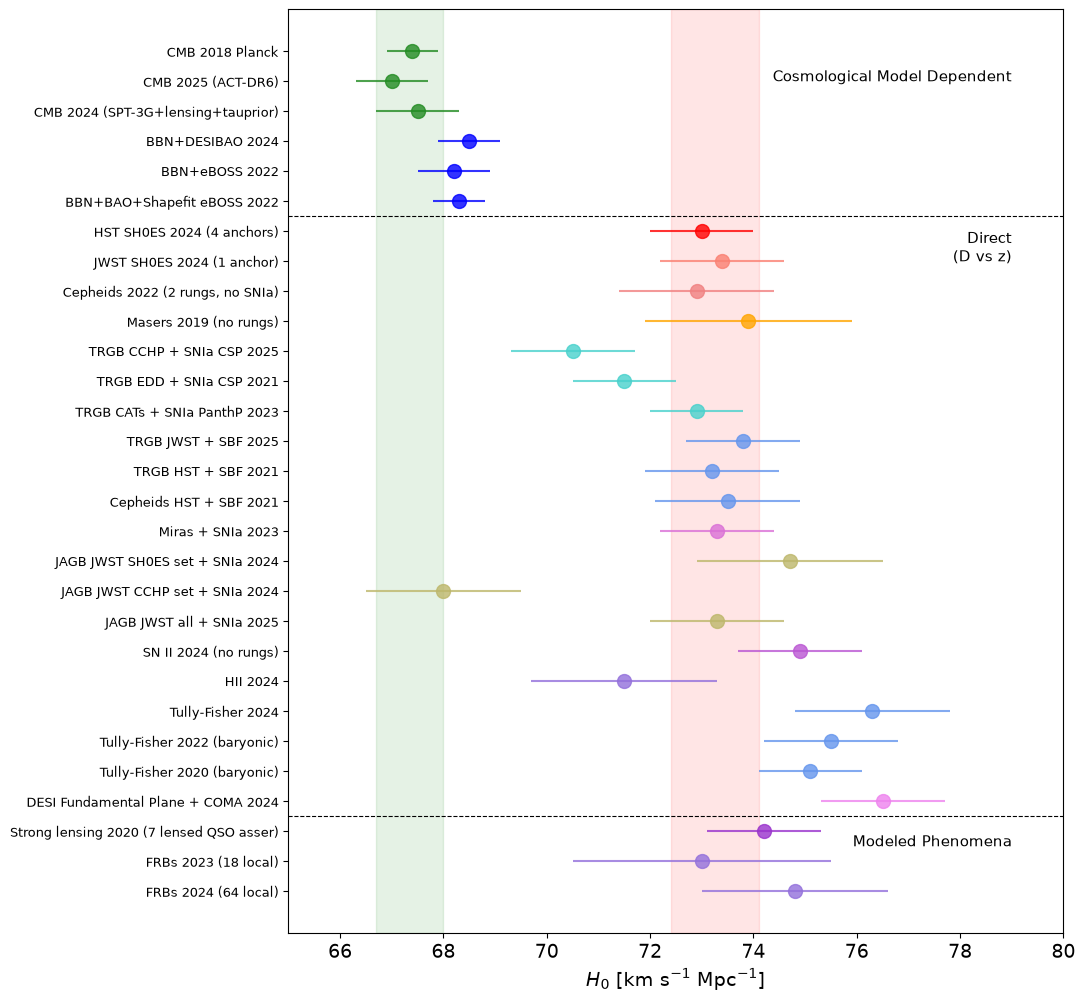

In [ ]:
# Configuración de los datos (Valores aproximados basados en la imagen)
# Formato: (Etiqueta, Valor, Error, Color)
data_cosmo = [
    ("CMB 2018 Planck", 67.4, 0.5, 'forestgreen'),
    ("CMB 2025 (ACT-DR6)", 67.0, 0.7, 'forestgreen'),
    ("CMB 2024 (SPT-3G+lensing+tauprior)", 67.5, 0.8, 'forestgreen'),
    ("BBN+DESIBAO 2024", 68.5, 0.6, 'blue'),
    ("BBN+eBOSS 2022", 68.2, 0.7, 'blue'),
    ("BBN+BAO+Shapefit eBOSS 2022", 68.3, 0.5, 'blue'),
]

data_direct = [
    ("HST SH0ES 2024 (4 anchors)", 73.0, 1.0, 'red'),
    ("JWST SH0ES 2024 (1 anchor)", 73.4, 1.2, 'salmon'),
    ("Cepheids 2022 (2 rungs, no SNIa)", 72.9, 1.5, 'lightcoral'),
    ("Masers 2019 (no rungs)", 73.9, 2.0, 'orange'),
    ("TRGB CCHP + SNIa CSP 2025", 70.5, 1.2, 'mediumturquoise'),
    ("TRGB EDD + SNIa CSP 2021", 71.5, 1.0, 'mediumturquoise'),
    ("TRGB CATs + SNIa PanthP 2023", 72.9, 0.9, 'mediumturquoise'),
    ("TRGB JWST + SBF 2025", 73.8, 1.1, 'cornflowerblue'),
    ("TRGB HST + SBF 2021", 73.2, 1.3, 'cornflowerblue'),
    ("Cepheids HST + SBF 2021", 73.5, 1.4, 'cornflowerblue'),
    ("Miras + SNIa 2023", 73.3, 1.1, 'orchid'),
    ("JAGB JWST SH0ES set + SNIa 2024", 74.7, 1.8, 'darkkhaki'),
    ("JAGB JWST CCHP set + SNIa 2024", 68.0, 1.5, 'darkkhaki'),
    ("JAGB JWST all + SNIa 2025", 73.3, 1.3, 'darkkhaki'),
    ("SN II 2024 (no rungs)", 74.9, 1.2, 'mediumorchid'),
    ("HII 2024", 71.5, 1.8, 'mediumpurple'),
    ("Tully-Fisher 2024", 76.3, 1.5, 'cornflowerblue'),
    ("Tully-Fisher 2022 (baryonic)", 75.5, 1.3, 'cornflowerblue'),
    ("Tully-Fisher 2020 (baryonic)", 75.1, 1.0, 'cornflowerblue'),
    ("DESI Fundamental Plane + COMA 2024", 76.5, 1.2, 'violet'),
]

data_modeled = [
    ("Strong lensing 2020 (7 lensed QSO asser)", 74.2, 1.1, 'darkorchid'),
    ("FRBs 2023 (18 local)", 73.0, 2.5, 'mediumpurple'),
    ("FRBs 2024 (64 local)", 74.8, 1.8, 'mediumpurple'),
]

# Unificar datos y calcular posiciones Y
all_data = data_cosmo + data_direct + data_modeled
labels = [d[0] for d in all_data]
values = [d[1] for d in all_data]
errors = [d[2] for d in all_data]
colors = [d[3] for d in all_data]
y_pos = np.arange(len(all_data))

# Crear la figura
fig, ax = plt.subplots(figsize=(10, 12))

# Dibujar las bandas de fondo (Sombreado verde y rosa)
ax.axvspan(66.7, 68.0, color='green', alpha=0.1, zorder=0)
ax.axvspan(72.4, 74.1, color='red', alpha=0.1, zorder=0)

# Dibujar puntos con barras de error
for i in range(len(all_data)):
    ax.errorbar(values[i], i, xerr=errors[i], fmt='o', color=colors[i], 
                markersize=10, capsize=0, elinewidth=1.5, alpha=0.8)

# Configurar ejes y etiquetas
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=9)
ax.invert_yaxis()  # Para que el primer dato esté arriba
ax.set_xlabel(r'$H_0$ [km s$^{-1}$ Mpc$^{-1}$]', fontsize=14)
ax.set_xlim(65, 80)

# Líneas divisorias horizontales
ax.axhline(y=len(data_cosmo) - 0.5, color='black', linestyle='--', linewidth=0.8)
ax.axhline(y=len(data_cosmo) + len(data_direct) - 0.5, color='black', linestyle='--', linewidth=0.8)

# Anotaciones de secciones
ax.text(79, 1, "Cosmological Model Dependent", ha='right', fontsize=11)
ax.text(79, 7, "Direct\n(D vs z)", ha='right', fontsize=11)
ax.text(79, 26.5, "Modeled Phenomena", ha='right', fontsize=11)

# Estética final
ax.xaxis.set_ticks_position('bottom')
ax.tick_params(axis='x', labelsize=14)

plt.show()